# HW4

Naim El Rouwadi | Student ID: 261031398

## Setup

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import scipy
from scipy.optimize import brentq, minimize
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import display, Image

ROOT = Path.cwd()
if (ROOT / "HW4" / "261031398_HW4.ipynb").exists():
    ROOT = ROOT / "HW4"
FIGURES = ROOT / "figures"
RESULTS = ROOT / "results"
TABLES = ROOT / "overleaf" / "tables"
for folder in (FIGURES, RESULTS, TABLES):
    folder.mkdir(parents=True, exist_ok=True)

np.set_printoptions(precision=10, suppress=True)
plt.rcParams.update({"font.size": 11, "figure.dpi": 120,
                     "axes.grid": True, "grid.alpha": 0.20})
COLORS = {"penalty": "#C44E52", "AL": "#2878B5", "fixed": "#9872AC",
          "optimum": "#27834C", "feasible": "#DDEDDD"}
START = np.array([0.0, 3.0])
# The L09 outer loops and BFGS method are retained. Exact gradients are
# supplied to reduce finite-difference error as the penalty parameter shrinks.
SOLVER_OPTIONS = {"gtol": 1e-8, "maxiter": 2000}

def print_table(title, table):
    print(title)
    print(table.to_string(index=False, float_format=lambda value: f"{value:.10g}"))
    print()

def latex_table(filename, headers, rows, small="small"):
    lines = [r"\begin{center}", "\\" + small,
             r"\setlength{\tabcolsep}{4pt}",
             r"\begin{tabular}{" + "r" * len(headers) + "}",
             r"\toprule", " & ".join(headers) + r" \\", r"\midrule"]
    lines += [" & ".join(row) + r" \\" for row in rows]
    lines += [r"\bottomrule", r"\end{tabular}", r"\end{center}"]
    (TABLES / filename).write_text("\n".join(lines) + "\n", encoding="utf-8")

def sci(value):
    if value == 0:
        return "$0$"
    mantissa, exponent = f"{value:.3e}".split("e")
    return rf"${mantissa}\times10^{{{int(exponent)}}}$"

print(f"NumPy {np.__version__} | SciPy {scipy.__version__}")

NumPy 2.5.3 | SciPy 1.18.1


## Question 2

### 2(a)

In [2]:
def f(x):
    return float(x[0]**2 + (x[1] - 3.0)**2)

def grad_f(x):
    return np.array([2.0*x[0], 2.0*(x[1] - 3.0)])

def g(x):
    return float(x[1]**2 - 2.0*x[0])

def grad_g(x):
    return np.array([-2.0, 2.0*x[1]])

HESS_G = np.diag([0.0, 2.0])

# Numerical part only; the KKT derivation is left for the written report.
x2_star = brentq(lambda y: y**3 + 2.0*y - 6.0, 0.0, 3.0, xtol=1e-14)
x_star = np.array([x2_star**2 / 2.0, x2_star])
mu_star = x_star[0]
f_star = f(x_star)

reference = pd.DataFrame([{
    "x1*": x_star[0], "x2*": x_star[1], "f(x*)": f_star,
    "mu*": mu_star, "g(x*)": g(x_star),
    "KKT stationarity norm": np.linalg.norm(grad_f(x_star) + mu_star*grad_g(x_star))
}])
reference.to_csv(RESULTS / "q2a_reference.csv", index=False)
print_table("2(a) - Numerical solution of the cubic", reference)
latex_table("q2a_reference.tex", [r"$x_1^*$", r"$x_2^*$", r"$f(x^*)$", r"$\mu^*$"],
            [[f"{v:.9f}" for v in [*x_star, f_star, mu_star]]])

2(a) - Numerical solution of the cubic
        x1*         x2*       f(x*)         mu*  g(x*)  KKT stationarity norm
1.060207156 1.456164246 3.507468048 1.060207156      0        8.881784197e-16



### 2(b)

In [3]:
# Adapted from L09_penalty_and_barrier_methods.ipynb, run_penalty.
# https://github.com/Ahmed-Bayoumy/MECH559/blob/DEV/L09/L09_penalty_and_barrier_methods.ipynb
def T_penalty(x, r):
    return f(x) + max(0.0, g(x))**2 / r

def grad_T_penalty(x, r):
    return grad_f(x) + (2.0/r)*max(0.0, g(x))*grad_g(x)

def hess_T_penalty(x, r):
    violation = g(x)
    if violation > 0.0:
        v = grad_g(x)
        return 2.0*np.eye(2) + (2.0/r)*(np.outer(v, v) + violation*HESS_G)
    if violation < 0.0:
        return 2.0*np.eye(2)
    # The squared hinge is C1; its classical Hessian need not exist at g=0.
    raise ValueError("The penalty Hessian is not defined exactly on g=0.")

def penalty_reference(r):
    # Independent stationary-point check of each unconstrained subproblem.
    # This root is used only for diagnostics, never as the BFGS iterate.
    a = 2.0 + r/2.0
    y = brentq(lambda y: y**3 + a*y - 3.0*a, 0.0, 3.0, xtol=1e-14)
    return np.array([y*y/a, y])

def run_penalty(x0, r0=1.0, beta=0.1, n_outer=7):
    x = np.array(x0, dtype=float)
    path = [x.copy()]
    rows, diagnostics = [], []
    for k in range(n_outer):
        r = r0*beta**k
        res = minimize(T_penalty, x, args=(r,), jac=grad_T_penalty,
                       method="BFGS", options=SOLVER_OPTIONS)
        x = res.x.copy()
        if not np.all(np.isfinite(x)):
            raise RuntimeError(f"Non-finite penalty iterate at k={k}")
        path.append(x.copy())
        rows.append({"k": k, "r_k": r, "x1": x[0], "x2": x[1],
                     "f(x_k)": f(x), "g(x_k)": g(x),
                     "mu_k": 2.0/r*max(0.0, g(x)),
                     "||x_k-x*||": np.linalg.norm(x-x_star),
                     "cond2(H_T)": np.linalg.cond(hess_T_penalty(x, r), 2)})
        diagnostics.append({"k": k, "success": bool(res.success),
                            "BFGS steps": res.nit,
                            "||grad T||": np.linalg.norm(grad_T_penalty(x, r)),
                            "subproblem error": np.linalg.norm(x-penalty_reference(r)),
                            "message": str(res.message)})
    return np.array(path), pd.DataFrame(rows), pd.DataFrame(diagnostics)

penalty_path, penalty_table, penalty_diagnostics = run_penalty(START)
penalty_table.to_csv(RESULTS / "q2b_penalty.csv", index=False)
penalty_diagnostics.to_csv(RESULTS / "q2b_solver_diagnostics.csv", index=False)
print("k=0 is the minimizer at r=1; the supplied initial guess is stored separately.")
print_table("2(b) - Penalty method", penalty_table)
print_table("2(b) - BFGS diagnostics (reported without replacing failed solves)", penalty_diagnostics)
latex_table("q2b_penalty.tex",
    ["$k$", "$r_k$", "$x_{1,k}$", "$x_{2,k}$", "$f(x_k)$", "$g(x_k)$", r"$\mu_k$",
     r"$\|x_k-x^*\|_2$", r"$\kappa_2(H_T)$"],
    [[str(int(row["k"])), f"$10^{{-{int(row['k'])}}}$" if row["k"] else "$1$",
      f"{row['x1']:.7f}", f"{row['x2']:.7f}", f"{row['f(x_k)']:.7f}",
      sci(row["g(x_k)"]), f"{row['mu_k']:.7f}", sci(row["||x_k-x*||"]),
      sci(row["cond2(H_T)"])] for row in penalty_table.to_dict("records")], "scriptsize")

k=0 is the minimizer at r=1; the supplied initial guess is stored separately.
2(b) - Penalty method
 k    r_k           x1          x2      f(x_k)          g(x_k)         mu_k      ||x_k-x*||  cond2(H_T)
 0      1 0.9483498899 1.539764503 3.031655221    0.4741749445 0.9483498889    0.1396461631 11.96071895
 1    0.1  1.047365052 1.465298043 3.452283647   0.05236825242  1.047365048   0.01575899394 95.87381352
 2   0.01  1.058903216 1.457086459 3.501858217  0.005294516083  1.058903217  0.001597102122 934.3476155
 3  0.001  1.060076557 1.456256554 3.506906133 0.0005300382639  1.060076528 0.0001599278432 9319.022198
 4 0.0001  1.060194095 1.456173478 3.507411847 5.300970483e-05  1.060194097 1.599464746e-05 93165.76122
 5  1e-05   1.06020585 1.456165169 3.507462428 5.301034861e-06  1.060206972  1.59950114e-06 931632.9014
 6  1e-06  1.060207025 1.456164338 3.507467486 5.301035126e-07  1.060207025 1.599501047e-07 9316307.046

2(b) - BFGS diagnostics (reported without replacing failed solves)


### 2(c)

In [4]:
# Adapted from L09_augmented_lagrangian_method.ipynb.
# https://github.com/Ahmed-Bayoumy/MECH559/blob/DEV/L09/L09_augmented_lagrangian_method.ipynb
def T_augmented(x, r, mu):
    return f(x) + mu*g(x) + max(0.0, g(x))**2/r

def grad_T_augmented(x, r, mu):
    return grad_f(x) + (mu + 2.0/r*max(0.0, g(x)))*grad_g(x)

def run_augmented_lagrangian(x0, mu0=0.0, r=1.0, n_outer=8):
    x = np.array(x0, dtype=float)
    mu = float(mu0)
    path = [x.copy()]
    rows, diagnostics = [], []
    for k in range(n_outer):
        # Row k pairs the input multiplier mu_k with the resulting minimizer x_k.
        mu_k = mu
        res = minimize(T_augmented, x, args=(r, mu_k), jac=grad_T_augmented,
                       method="BFGS", options=SOLVER_OPTIONS)
        x = res.x.copy()
        if not np.all(np.isfinite(x)):
            raise RuntimeError(f"Non-finite AL iterate at k={k}")
        mu = mu_k + 2.0/r*g(x)  # Assigned, unprojected multiplier update.
        path.append(x.copy())
        rows.append({"k": k, "mu_k (input)": mu_k, "x1": x[0], "x2": x[1],
                     "g(x_k)": g(x), "||x_k-x*||": np.linalg.norm(x-x_star),
                     "mu_(k+1)": mu})
        diagnostics.append({"k": k, "success": bool(res.success),
                            "BFGS steps": res.nit,
                            "||grad T||": np.linalg.norm(grad_T_augmented(x, r, mu_k)),
                            "message": str(res.message)})
    return np.array(path), pd.DataFrame(rows), pd.DataFrame(diagnostics)

al_path, al_table, al_diagnostics = run_augmented_lagrangian(START)
# Same objective and same r at every outer call, with the course warm start.
fixed_path, fixed_table, fixed_diagnostics = run_penalty(START, beta=1.0, n_outer=8)

al_table.to_csv(RESULTS / "q2c_augmented_lagrangian.csv", index=False)
al_diagnostics.to_csv(RESULTS / "q2c_solver_diagnostics.csv", index=False)
fixed_table.to_csv(RESULTS / "q2c_fixed_penalty.csv", index=False)
fixed_diagnostics.to_csv(RESULTS / "q2c_fixed_penalty_diagnostics.csv", index=False)
print("Eight outer solves: k=0,...,7. mu_k is the input; mu_(k+1) is the update.")
print_table("2(c) - Augmented Lagrangian, fixed r=1", al_table)
print_table("2(c) - BFGS diagnostics", al_diagnostics)
print_table("2(c) - Repeated plain penalty minimization, fixed r=1",
            fixed_table[["k", "x1", "x2", "f(x_k)", "g(x_k)", "||x_k-x*||"]])
latex_table("q2c_augmented.tex",
    ["$k$", r"$\mu_k$ (input)", "$x_{1,k}$", "$x_{2,k}$", "$g(x_k)$",
     r"$\|x_k-x^*\|_2$", r"$\mu_{k+1}$"],
    [[str(int(row["k"])), f"{row['mu_k (input)']:.9f}", f"{row['x1']:.9f}",
      f"{row['x2']:.9f}", sci(row["g(x_k)"]), sci(row["||x_k-x*||"]),
      f"{row['mu_(k+1)']:.9f}"] for row in al_table.to_dict("records")], "scriptsize")
latex_table("q2c_fixed_penalty.tex",
    ["$k$", "$x_{1,k}$", "$x_{2,k}$", "$f(x_k)$", "$g(x_k)$", r"$\|x_k-x^*\|_2$"],
    [[str(int(row["k"])), f"{row['x1']:.8f}", f"{row['x2']:.8f}",
      f"{row['f(x_k)']:.8f}", f"{row['g(x_k)']:.8f}", sci(row["||x_k-x*||"])]
     for row in fixed_table.to_dict("records")], "small")

Eight outer solves: k=0,...,7. mu_k is the input; mu_(k+1) is the update.
2(c) - Augmented Lagrangian, fixed r=1
 k  mu_k (input)           x1          x2          g(x_k)      ||x_k-x*||     mu_(k+1)
 0             0 0.9483498899 1.539764503    0.4741749445    0.1396461631 0.9483498889
 1  0.9483498889  1.047987413 1.464852753   0.04981876203   0.01499374096  1.047987413
 2   1.047987413  1.058867406 1.457111804  0.005439996678  0.001640973845  1.058867406
 3   1.058867406   1.06006021 1.456268115 0.0005964021673 0.0001799492339  1.060060211
 4   1.060060211  1.060191038 1.456175639 6.541376775e-05 1.973732117e-05  1.060191038
 5   1.060191038  1.060205388 1.456165496 7.174894741e-06 2.164891591e-06  1.060205388
 6   1.060205388  1.060206962 1.456164383 7.857137083e-07 2.371176245e-07  1.060206959
 7   1.060206959  1.060207134 1.456164261 8.832815279e-08 2.681198454e-08  1.060207136

2(c) - BFGS diagnostics
 k  success  BFGS steps      ||grad T||                               message
 

### 2(d)

Out[5]: 1093


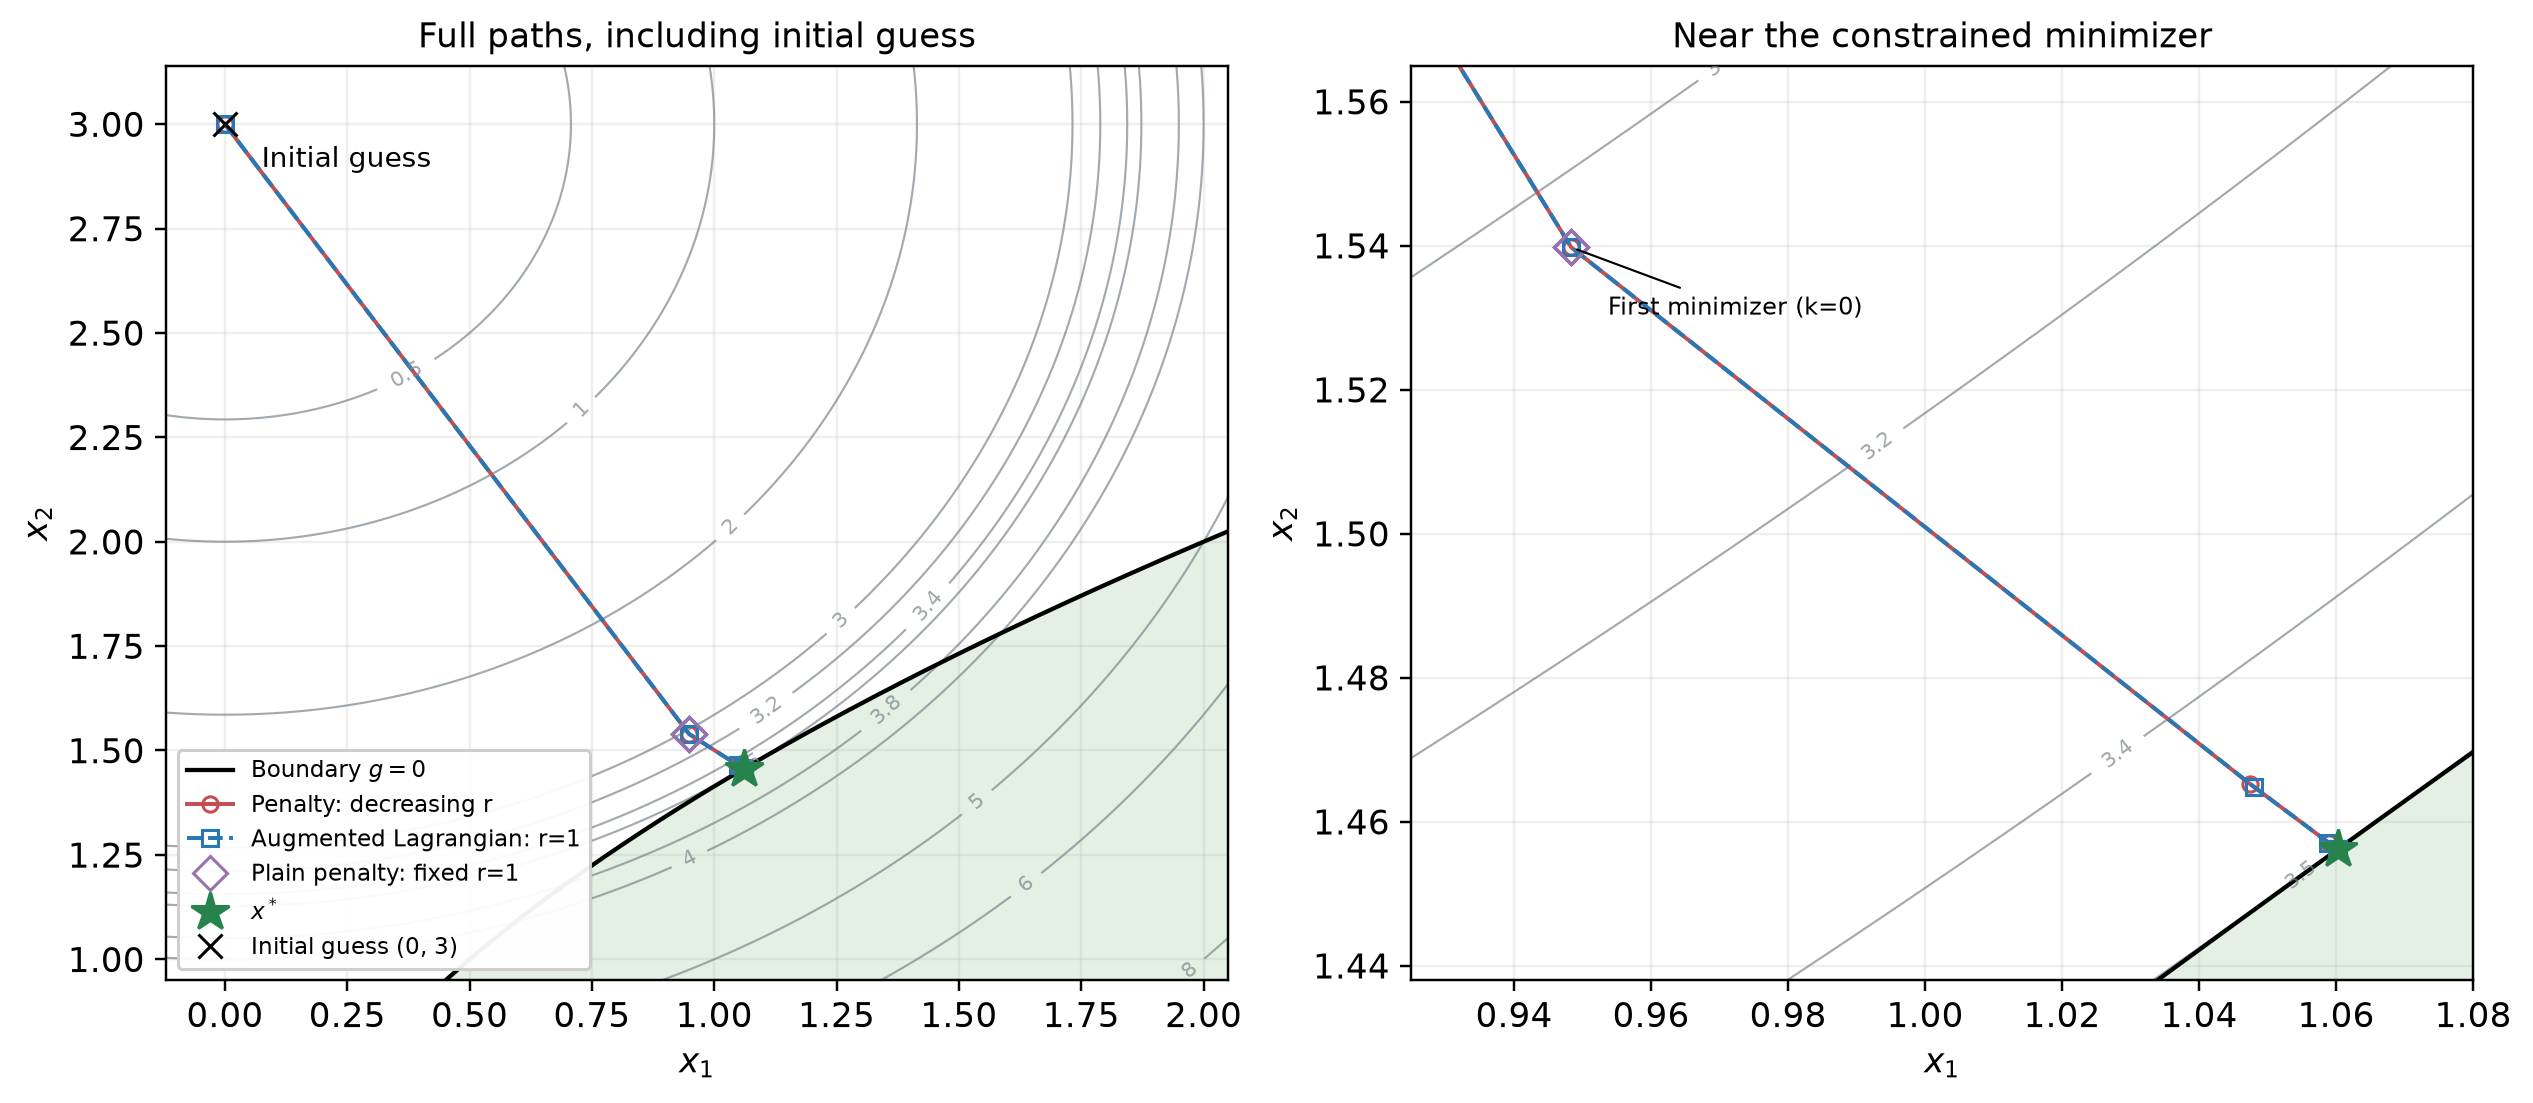

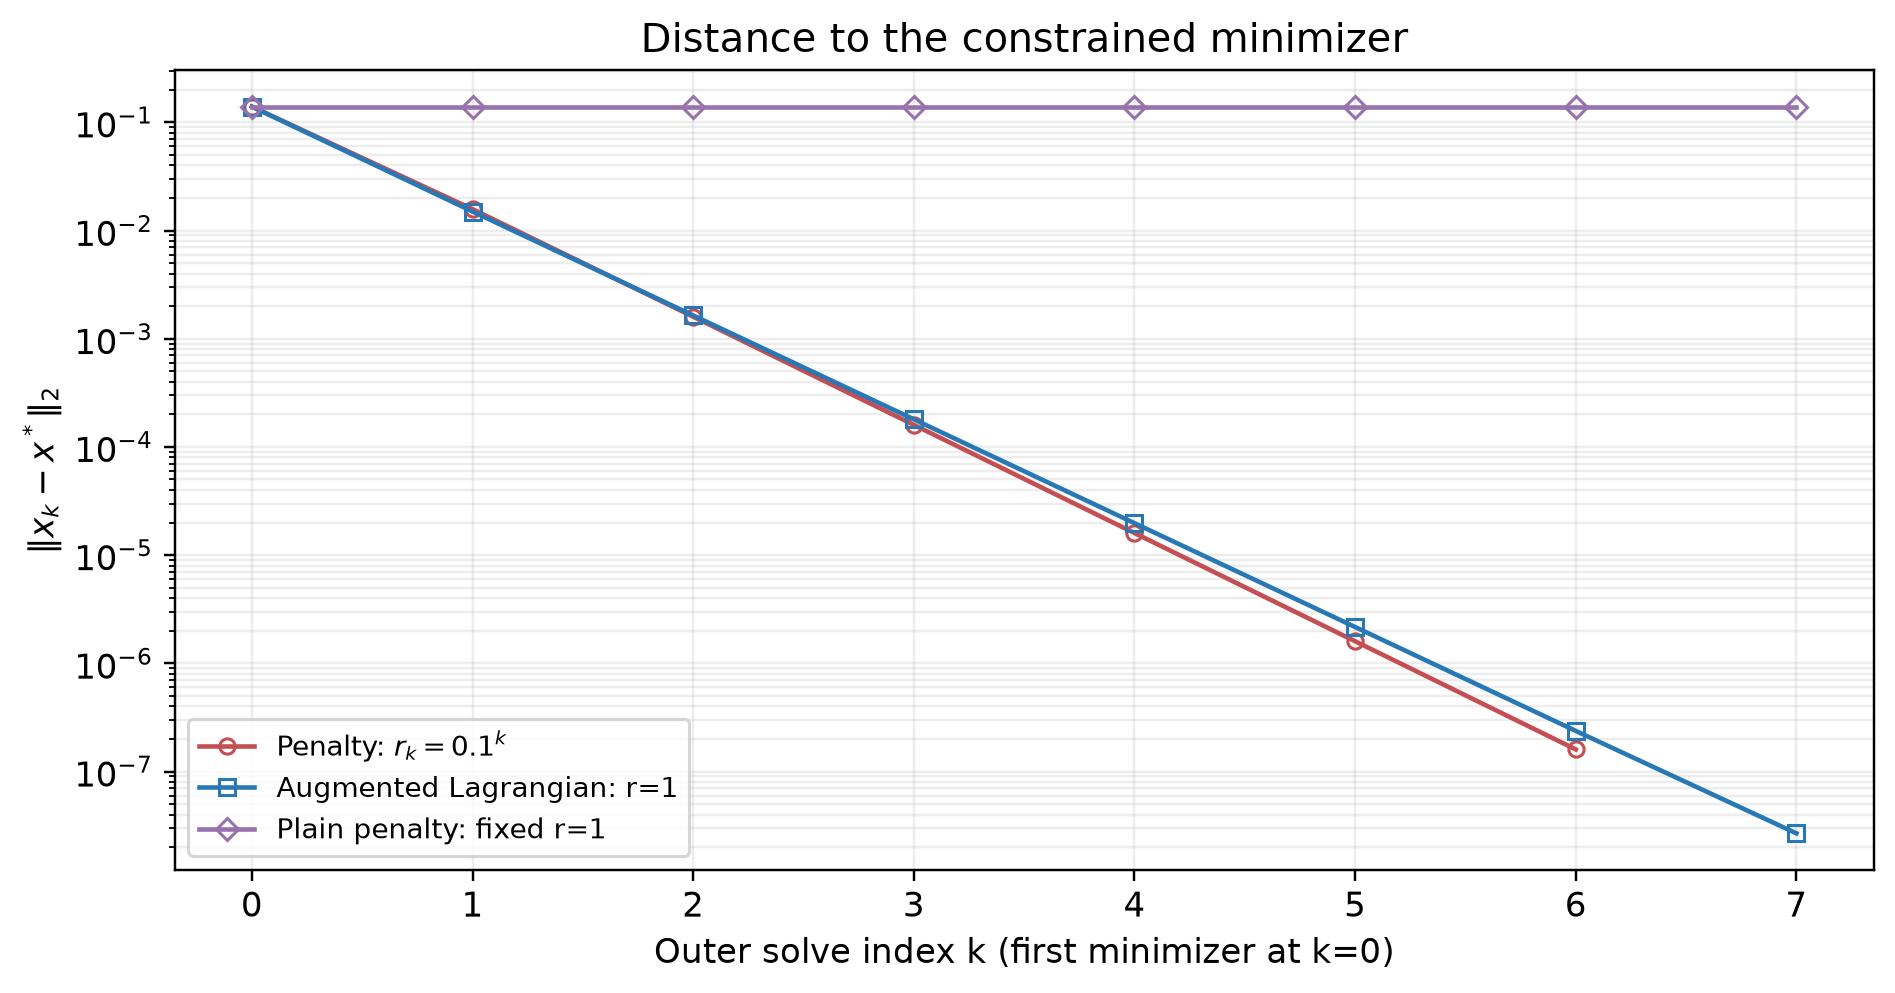

In [5]:
def draw_contours(ax, limits, levels):
    xmin, xmax, ymin, ymax = limits
    xx, yy = np.meshgrid(np.linspace(xmin, xmax, 500), np.linspace(ymin, ymax, 500))
    ff = xx**2 + (yy-3.0)**2
    ax.contourf(xx, yy, (yy**2-2*xx <= 0).astype(float), levels=[0.5, 1.5],
                colors=[COLORS["feasible"]], alpha=0.8)
    contours = ax.contour(xx, yy, ff, levels=levels, colors="#7B858D", alpha=0.70, linewidths=0.7)
    ax.clabel(contours, inline=True, fontsize=7, fmt="%.2g")
    boundary_y = np.linspace(ymin, ymax, 600)
    ax.plot(boundary_y**2/2, boundary_y, "k-", lw=1.4, label=r"Boundary $g=0$")
    ax.set(xlim=(xmin, xmax), ylim=(ymin, ymax), xlabel=r"$x_1$", ylabel=r"$x_2$")

fig, axes = plt.subplots(1, 2, figsize=(11.4, 4.9), layout="constrained")
for ax, limits, title in [
    (axes[0], (-0.12, 2.05, 0.95, 3.14), "Full paths, including initial guess"),
    (axes[1], (0.925, 1.08, 1.438, 1.565), "Near the constrained minimizer")]:
    draw_contours(ax, limits, [0.5, 1, 2, 3, 3.2, 3.4, f_star, 3.8, 4, 5, 6, 8])
    for path, label, color, marker in [
        (penalty_path, "Penalty: decreasing r", COLORS["penalty"], "o"),
        (al_path, "Augmented Lagrangian: r=1", COLORS["AL"], "s")]:
        ax.plot(path[:,0], path[:,1], linestyle="--" if marker=="s" else "-",
                marker=marker, ms=5, mfc="none", lw=1.3, color=color, label=label)
    # All fixed-r minimizers coincide to solver precision; display their location.
    ax.plot(fixed_path[1:,0], fixed_path[1:,1], "D", ms=8, mfc="none",
            color=COLORS["fixed"], label="Plain penalty: fixed r=1")
    ax.plot(*x_star, "*", color=COLORS["optimum"], ms=13, label=r"$x^*$", zorder=10)
    ax.set_title(title, fontsize=11)
axes[0].plot(*START, "kx", ms=8, label="Initial guess (0, 3)")
axes[0].annotate("Initial guess", START, xytext=(12, -14), textcoords="offset points", fontsize=9)
axes[1].annotate("First minimizer (k=0)", penalty_path[1], xytext=(12,-22),
                 textcoords="offset points", fontsize=8, arrowprops={"arrowstyle":"-", "lw":0.7})
axes[0].legend(loc="lower left", fontsize=7.5, framealpha=0.95)
fig.savefig(FIGURES / "q2d_contours.png", dpi=220, bbox_inches="tight")
plt.close(fig)
display(Image(filename=str(FIGURES / "q2d_contours.png")))

fig, ax = plt.subplots(figsize=(8.5, 4.4), layout="constrained")
for table, label, color, marker in [
    (penalty_table, r"Penalty: $r_k=0.1^k$", COLORS["penalty"], "o"),
    (al_table, "Augmented Lagrangian: r=1", COLORS["AL"], "s"),
    (fixed_table, "Plain penalty: fixed r=1", COLORS["fixed"], "D")]:
    ax.semilogy(table["k"], table["||x_k-x*||"], marker=marker, color=color,
                lw=1.5, ms=5, mfc="none", label=label)
ax.set(xlabel="Outer solve index k (first minimizer at k=0)",
       ylabel=r"$\|x_k-x^*\|_2$", xticks=np.arange(8),
       title="Distance to the constrained minimizer")
ax.legend(fontsize=9)
ax.grid(True, which="both", alpha=0.22)
fig.savefig(FIGURES / "q2d_convergence.png", dpi=220, bbox_inches="tight")
plt.close(fig)
display(Image(filename=str(FIGURES / "q2d_convergence.png")))

summary = {
    "x_star": x_star.tolist(), "f_star": f_star, "mu_star": float(mu_star),
    "solver": "BFGS with analytical gradients", "options": SOLVER_OPTIONS,
    "penalty_final": penalty_table.iloc[-1].to_dict(),
    "al_final": al_table.iloc[-1].to_dict(),
    "fixed_penalty_final": fixed_table.iloc[-1].to_dict(),
}
(RESULTS / "summary.json").write_text(json.dumps(summary, indent=2), encoding="utf-8")

## Question 3

### 3(b)

In [6]:
# Adapted from Part 2 of the course notebook, including its active-set QP solver.
# https://github.com/Ahmed-Bayoumy/MECH559/blob/DEV/L09/L09_sqp.ipynb
def f3(x):
    x1, x2, x3, x4 = x
    return float(x1*x1 + x2*x2 + 2*x3*x3 + x4*x4
                 - 5*x1 - 5*x2 - 21*x3 + 7*x4)

def grad_f3(x):
    return np.array([2*x[0]-5, 2*x[1]-5, 4*x[2]-21, 2*x[3]+7])

def g3(x):
    x1, x2, x3, x4 = x
    return np.array([
        x1*x1+x2*x2+x3*x3+x4*x4+x1-x2+x3-x4-8,
        x1*x1+2*x2*x2+x3*x3+2*x4*x4-x1-x4-10,
        2*x1*x1+x2*x2+x3*x3+2*x1-x2-x4-5,
    ])

def jac_g3(x):
    x1, x2, x3, x4 = x
    return np.array([[2*x1+1, 2*x2-1, 2*x3+1, 2*x4-1],
                     [2*x1-1, 4*x2, 2*x3, 4*x4-1],
                     [4*x1+2, 2*x2-1, 2*x3, -1]])

HESS_F3 = np.diag([2., 2., 4., 2.])
HESS_G3 = np.array([np.diag([2., 2., 2., 2.]),
                    np.diag([2., 4., 2., 4.]),
                    np.diag([4., 2., 2., 0.])])

def hess_L3(mu):
    return HESS_F3 + np.einsum('j,jab->ab', mu, HESS_G3)

def solve_equality_kkt3(H, c, A, b, working_set):
    n = H.shape[0]
    idx = sorted(working_set)
    if not idx:
        return np.linalg.solve(H, -c), {}
    Aw, bw = A[idx], b[idx]
    m = len(idx)
    KKT = np.block([[H, Aw.T], [Aw, np.zeros((m, m))]])
    sol = np.linalg.solve(KKT, np.concatenate([-c, bw]))
    return sol[:n], dict(zip(idx, sol[n:]))

def solve_qp_active_set3(H, c, A, b, working_set0, max_iter=30):
    # QP: min 0.5*dx.T*H*dx + c.T*dx subject to A*dx <= b.
    working = set(working_set0)
    for _ in range(max_iter):
        dx, mu = solve_equality_kkt3(H, c, A, b, working)
        residual = A @ dx - b
        violated = [j for j in range(A.shape[0])
                    if j not in working and residual[j] > 1e-10]
        negative_mu = [j for j in working if mu[j] < -1e-10]
        if not violated and not negative_mu:
            return dx, mu
        if violated:
            working.add(violated[np.argmax(residual[violated])])
        else:
            working.remove(min(negative_mu, key=lambda j: mu[j]))
    raise RuntimeError('Inner QP active-set method did not converge.')

def sqp3(x0, max_iter=200, tol=1e-8, merit_weight=10.0):
    x = np.asarray(x0, dtype=float).copy()
    mu = np.zeros(3)
    path, rows, diagnostics = [x.copy()], [], []
    reason = 'maximum iterations'
    merit = lambda xx: f3(xx) + merit_weight*np.maximum(g3(xx), 0.).sum()
    for k in range(max_iter):
        gk, Ak = g3(x), jac_g3(x)
        # mu contains the PREVIOUS QP multipliers, initially all zero.
        Wk = hess_L3(mu)
        active_guess = set(np.flatnonzero(gk > -1e-6))
        dx, qp_mu = solve_qp_active_set3(Wk, grad_f3(x), Ak, -gk, active_guess)
        mu_next = np.array([qp_mu.get(j, 0.) for j in range(3)])
        row = {'k': k, **{f'x{j+1}': x[j] for j in range(4)},
               'f(x_k)': f3(x), 'max violation': max(0., gk.max()),
               '||grad L||': np.linalg.norm(grad_f3(x) + Ak.T @ mu),
               '||dx||': np.linalg.norm(dx), 'alpha': np.nan,
               **{f'mu{j+1} (input)': mu[j] for j in range(3)}}
        diag = {'k': k,
                'QP stationarity': np.linalg.norm(Wk @ dx + grad_f3(x) + Ak.T @ mu_next),
                'QP max violation': max(0., (Ak @ dx + gk).max()),
                'QP complementarity': np.max(np.abs(mu_next*(Ak @ dx+gk))),
                'QP min multiplier': mu_next.min(),
                'min eigenvalue W': np.linalg.eigvalsh(Wk).min()}
        if np.linalg.norm(dx) <= tol:
            reason = 'step norm <= 1e-8'
            row['status'] = 'step tolerance; no step'
            rows.append(row)
            diagnostics.append(diag)
            break
        # Course merit function and halving rule; reject a failed search.
        alpha, m0, accepted = 1., merit(x), False
        for _ in range(30):
            trial = x + alpha*dx
            if merit(trial) < m0:
                accepted = True
                break
            alpha *= 0.5
        if not accepted:
            reason = 'merit line search found no decrease'
            row['status'] = 'line search stopped; no step'
            rows.append(row)
            diagnostics.append(diag)
            break
        row['alpha'], row['status'] = alpha, 'accepted'
        diag['merit decrease'] = m0 - merit(trial)
        rows.append(row)
        diagnostics.append(diag)
        x, mu = trial, mu_next
        path.append(x.copy())
    return {'x': x, 'mu': mu, 'path': np.array(path),
            'history': pd.DataFrame(rows), 'diagnostics': pd.DataFrame(diagnostics),
            'accepted steps': len(path)-1, 'QP solves': len(rows), 'reason': reason}

q3_start = np.zeros(4)
q3_reference = np.array([0., 1., 2., -1.])  # Part (a), used only for comparison.
q3_mu_reference = np.array([1., 0., 2.])
q3_sqp = sqp3(q3_start)
q3_history = q3_sqp['history']
q3_history.to_csv(RESULTS / 'q3b_sqp_iterations.csv', index=False)
q3_sqp['diagnostics'].to_csv(RESULTS / 'q3b_qp_diagnostics.csv', index=False)
print('Each row uses x_k and the SAME input mu_k that forms W_k.')
print('alpha advances x_k to x_(k+1); NaN means no step was taken.')
print_table('3(b) - SQP iteration history', q3_history)
print('Termination:', q3_sqp['reason'])
print('Accepted steps:', q3_sqp['accepted steps'], '| QP solves:', q3_sqp['QP solves'])
print('Final x:', q3_sqp['x'])
print('Final mu (last accepted QP multipliers):', q3_sqp['mu'])
print('Final f:', f3(q3_sqp['x']))
print('Final g:', g3(q3_sqp['x']))
print('Active constraints (|g_j| <= 1e-6):',
      (np.flatnonzero(np.abs(g3(q3_sqp['x'])) <= 1e-6)+1).tolist())
print('Distance to part (a):', np.linalg.norm(q3_sqp['x']-q3_reference))
print('Multiplier error:', np.linalg.norm(q3_sqp['mu']-q3_mu_reference))

latex_table('q3b_sqp_iterations.tex',
    ['$k$', '$x_{1,k}$', '$x_{2,k}$', '$x_{3,k}$', '$x_{4,k}$',
     '$f(x_k)$', r'$v_k$', r'$\|\nabla_x L_k\|_2$', r'$\alpha_k$'],
    [[str(int(row['k'])), *[f"{row[f'x{j+1}']:.7f}" for j in range(4)],
      f"{row['f(x_k)']:.7f}", sci(row['max violation']), sci(row['||grad L||']),
      '--' if pd.isna(row['alpha']) else f"{row['alpha']:.6g}"]
     for row in q3_history.to_dict('records')], 'scriptsize')

Each row uses x_k and the SAME input mu_k that forms W_k.
alpha advances x_k to x_(k+1); NaN means no step was taken.
3(b) - SQP iteration history
 k               x1           x2          x3            x4       f(x_k)   max violation      ||grad L||          ||dx||  alpha  mu1 (input)  mu2 (input)  mu3 (input)                  status
 0                0            0           0             0            0               0     23.23790008     7.075309181   0.25            0            0            0                accepted
 1             0.55        0.675         1.3        -0.825    -34.38125               0     15.89426626     1.875507309    0.5          0.2            0          0.2                accepted
 2      0.250745694  1.165961549 2.001301813   -0.58633433 -43.43866902    0.4122862544     1.005597454    0.4845824665      1  2.377217314            0  0.195969333                accepted
 3   -0.08008391819  1.024361774 2.117963457 -0.8891733947 -44.60493742       0.2525569     1

### 3(c)

In [7]:
# SciPy inequality functions must be nonnegative, hence -g and -jac_g.
q3_slsqp = minimize(f3, q3_start, jac=grad_f3, method='SLSQP',
    constraints=[{'type': 'ineq', 'fun': lambda x: -g3(x),
                  'jac': lambda x: -jac_g3(x)}],
    options={'ftol': 1e-12, 'maxiter': 200})
q3_comparison = pd.DataFrame([
    {'method': 'Custom SQP', **{f'x{j+1}': q3_sqp['x'][j] for j in range(4)},
     'f(x)': f3(q3_sqp['x']), 'max violation': max(0., g3(q3_sqp['x']).max()),
     '||x-x*||': np.linalg.norm(q3_sqp['x']-q3_reference),
     'iterations': q3_sqp['accepted steps']},
    {'method': 'SciPy SLSQP', **{f'x{j+1}': q3_slsqp.x[j] for j in range(4)},
     'f(x)': q3_slsqp.fun, 'max violation': max(0., g3(q3_slsqp.x).max()),
     '||x-x*||': np.linalg.norm(q3_slsqp.x-q3_reference),
     'iterations': q3_slsqp.nit},
])
print_table('3(c) - Comparison from x0 = (0, 0, 0, 0)', q3_comparison)
print('SLSQP success:', q3_slsqp.success, '|', q3_slsqp.message)
print('SLSQP settings: analytical gradients, ftol=1e-12, maxiter=200.')
print('Custom iterations count accepted steps; QP solves include the terminal check:',
      q3_sqp['QP solves'])
print('SLSQP iterations use OptimizeResult.nit.')
print('SLSQP constraint values:', g3(q3_slsqp.x))
q3_comparison.to_csv(RESULTS / 'q3c_comparison.csv', index=False)
latex_table('q3c_comparison.tex',
    ['Method', '$f(x)$', '$v$', r'$\|x-x^*\|_2$', 'Iterations'],
    [[row['method'], f"{row['f(x)']:.10f}", sci(row['max violation']),
      sci(row['||x-x*||']), str(int(row['iterations']))]
     for row in q3_comparison.to_dict('records')], 'small')
q3_summary = {'sqp': {'x': q3_sqp['x'].tolist(), 'mu': q3_sqp['mu'].tolist(),
    'f': f3(q3_sqp['x']), 'g': g3(q3_sqp['x']).tolist(),
    'accepted_steps': q3_sqp['accepted steps'], 'qp_solves': q3_sqp['QP solves'],
    'termination': q3_sqp['reason'],
    'stationarity_norm': float(np.linalg.norm(grad_f3(q3_sqp['x'])
                              + jac_g3(q3_sqp['x']).T @ q3_sqp['mu']))},
    'slsqp': {'x': q3_slsqp.x.tolist(), 'f': float(q3_slsqp.fun),
    'g': g3(q3_slsqp.x).tolist(), 'iterations': int(q3_slsqp.nit),
    'success': bool(q3_slsqp.success), 'message': str(q3_slsqp.message)}}
(RESULTS / 'q3_summary.json').write_text(json.dumps(q3_summary, indent=2), encoding='utf-8')

3(c) - Comparison from x0 = (0, 0, 0, 0)
     method               x1           x2  x3            x4         f(x)   max violation        ||x-x*||  iterations
 Custom SQP  8.055068716e-10 0.9999999992   2  -1.000000001 -44.00000001 5.412870152e-09 1.700962589e-09           6
SciPy SLSQP -4.779793711e-10            1   2 -0.9999999996          -44 6.838973832e-13 7.382308798e-10          18

SLSQP success: True | Optimization terminated successfully
SLSQP settings: analytical gradients, ftol=1e-12, maxiter=200.
Custom iterations count accepted steps; QP solves include the terminal check: 7
SLSQP iterations use OptimizeResult.nit.
SLSQP constraint values: [ 0.           -0.9999999989  0.          ]
Out[7]: 858


## Question 4

### 4(b)

In [8]:
# Provided problem, reduced-gradient, and restoration functions from
# HW4_GRG_template.ipynb. Names have a 4 suffix to keep Q2 and Q3 independent.
# GRG guide: Section 3 of the linked course notebook:
# https://github.com/Ahmed-Bayoumy/MECH559/blob/DEV/L09/L09_generalized_reduced_gradient.ipynb
def f4(x):
    x1, x2, x3, x4, x5 = x
    return (x1-x2)**2 + (x2-x3)**2 + (x3-x4)**2 + (x4-x5)**2

def grad_f4(x):
    x1, x2, x3, x4, x5 = x
    return np.array([2*(x1-x2), -2*(x1-x2)+2*(x2-x3),
                     -2*(x2-x3)+2*(x3-x4), -2*(x3-x4)+2*(x4-x5),
                     -2*(x4-x5)])

def h4(x):
    x1, x2, x3, x4, x5 = x
    return np.array([x1+x2**2+x3**3-3, x2-x3**2+x4-1, x1*x5-1])

def jac_h4(x):
    x1, x2, x3, x4, x5 = x
    return np.array([[1, 2*x2, 3*x3**2, 0, 0],
                     [0, 1, -2*x3, 1, 0],
                     [x5, 0, 0, 0, x1]], dtype=float)

D4, S4 = [1, 2], [0, 3, 4]
q4_start = np.array([2., np.sqrt(2.), -1., 2.-np.sqrt(2.), .5])

def reduced_gradient4(x):
    gf, J = grad_f4(x), jac_h4(x)
    return gf[D4] - gf[S4] @ np.linalg.solve(J[:, S4], J[:, D4])

def restore_state4(x, tol=1e-12, max_iter=50):
    x = x.copy()
    for _ in range(max_iter):
        hv = h4(x)
        if not np.all(np.isfinite(hv)):
            return x, False
        if np.linalg.norm(hv) < tol:
            return x, True
        x[S4] -= np.linalg.solve(jac_h4(x)[:, S4], hv)
    return x, np.linalg.norm(h4(x)) < tol

def grg4(x0, tol=1e-6, max_iter=5000, alpha0=1., eps=1e-4, beta=.5):
    x = np.array(x0, dtype=float)
    traj, gnorm = [x.copy()], [np.linalg.norm(reduced_gradient4(x))]
    steps = []
    for k in range(max_iter):
        dw = reduced_gradient4(x)
        if np.linalg.norm(dw) <= tol:
            break
        J = jac_h4(x)
        state_sensitivity = np.linalg.solve(J[:, S4], J[:, D4])
        alpha, accepted, restoration_failures = alpha0, False, 0
        for trial in range(60):
            dxd = -alpha*dw
            xn = x.copy()
            xn[D4] = x[D4] + dxd
            xn[S4] = x[S4] - state_sensitivity @ dxd
            prediction_residual = np.linalg.norm(h4(xn))
            try:
                xn, ok = restore_state4(xn)
            except np.linalg.LinAlgError:
                ok = False  # A singular restoration is a rejected trial.
            if not ok:
                restoration_failures += 1
            armijo_rhs = f4(x) - eps*alpha*np.dot(dw, dw)
            if ok and np.all(np.isfinite(xn)) and f4(xn) <= armijo_rhs:
                accepted = True
                break
            alpha *= beta
        if not accepted:
            raise RuntimeError(f'GRG line search failed at k={k}; no failed trial was accepted.')
        steps.append({'k': k, 'alpha': alpha, 'backtracks': trial,
                      'restoration failures': restoration_failures,
                      'prediction ||h||': prediction_residual,
                      'restored ||h||': np.linalg.norm(h4(xn)),
                      'f before': f4(x), 'f after': f4(xn),
                      'Armijo margin': armijo_rhs-f4(xn)})
        x = xn
        traj.append(x.copy())
        gnorm.append(np.linalg.norm(reduced_gradient4(x)))
    return np.array(traj), np.array(gnorm), pd.DataFrame(steps)

q4_traj, q4_gnorm, q4_steps = grg4(q4_start)
q4_xf = q4_traj[-1]
q4_converged = bool(q4_gnorm[-1] <= 1e-6)
q4_history = pd.DataFrame(q4_traj, columns=[f'x{j}' for j in range(1, 6)])
q4_history.insert(0, 'k', np.arange(len(q4_traj)))
q4_history['f(x)'] = [f4(x) for x in q4_traj]
q4_history['||grad w||'] = q4_gnorm
q4_history['||h||'] = [np.linalg.norm(h4(x)) for x in q4_traj]
q4_history.to_csv(RESULTS / 'q4b_grg_iterations.csv', index=False)
q4_steps.to_csv(RESULTS / 'q4b_line_search.csv', index=False)
q4_final_table = pd.DataFrame([{
    'iterations': len(q4_traj)-1, 'f(x)': f4(q4_xf),
    '||grad w||': q4_gnorm[-1], '||h||': np.linalg.norm(h4(q4_xf)),
    'converged': q4_converged}])
print('Initial h(x0):', h4(q4_start))
print('Initial reduced gradient (numerical check for part a):', reduced_gradient4(q4_start))
print('Final x:', q4_xf)
print_table('4(b) - GRG final results', q4_final_table)
print('Termination:', 'reduced-gradient tolerance' if q4_converged else '5000 iteration limit')
print('All accepted iterates, including k=0, saved in results/q4b_grg_iterations.csv.')
print('Largest accepted-point ||h||:', q4_history['||h||'].max())
print('Accepted alpha range:', q4_steps['alpha'].min(), q4_steps['alpha'].max())
latex_table('q4b_final.tex', ['Iterations', '$f(x)$', r'$\|\nabla w\|_2$', r'$\|h\|_2$'],
            [[str(len(q4_traj)-1), sci(f4(q4_xf)), sci(q4_gnorm[-1]),
              sci(np.linalg.norm(h4(q4_xf)))]])

Initial h(x0): [0. 0. 0.]
Initial reduced gradient (numerical check for part a): [ -3.1213203436 -18.3296897832]
Final x: [0.9999999623 1.0000000217 0.9999999981 0.9999999745 1.0000000377]
4(b) - GRG final results
 iterations            f(x)      ||grad w||           ||h||  converged
         47 8.635917294e-15 9.162429533e-07 3.575421669e-13       True

Termination: reduced-gradient tolerance
All accepted iterates, including k=0, saved in results/q4b_grg_iterations.csv.
Largest accepted-point ||h||: 9.09163756610572e-13
Accepted alpha range: 0.015625 0.125


### 4(c)

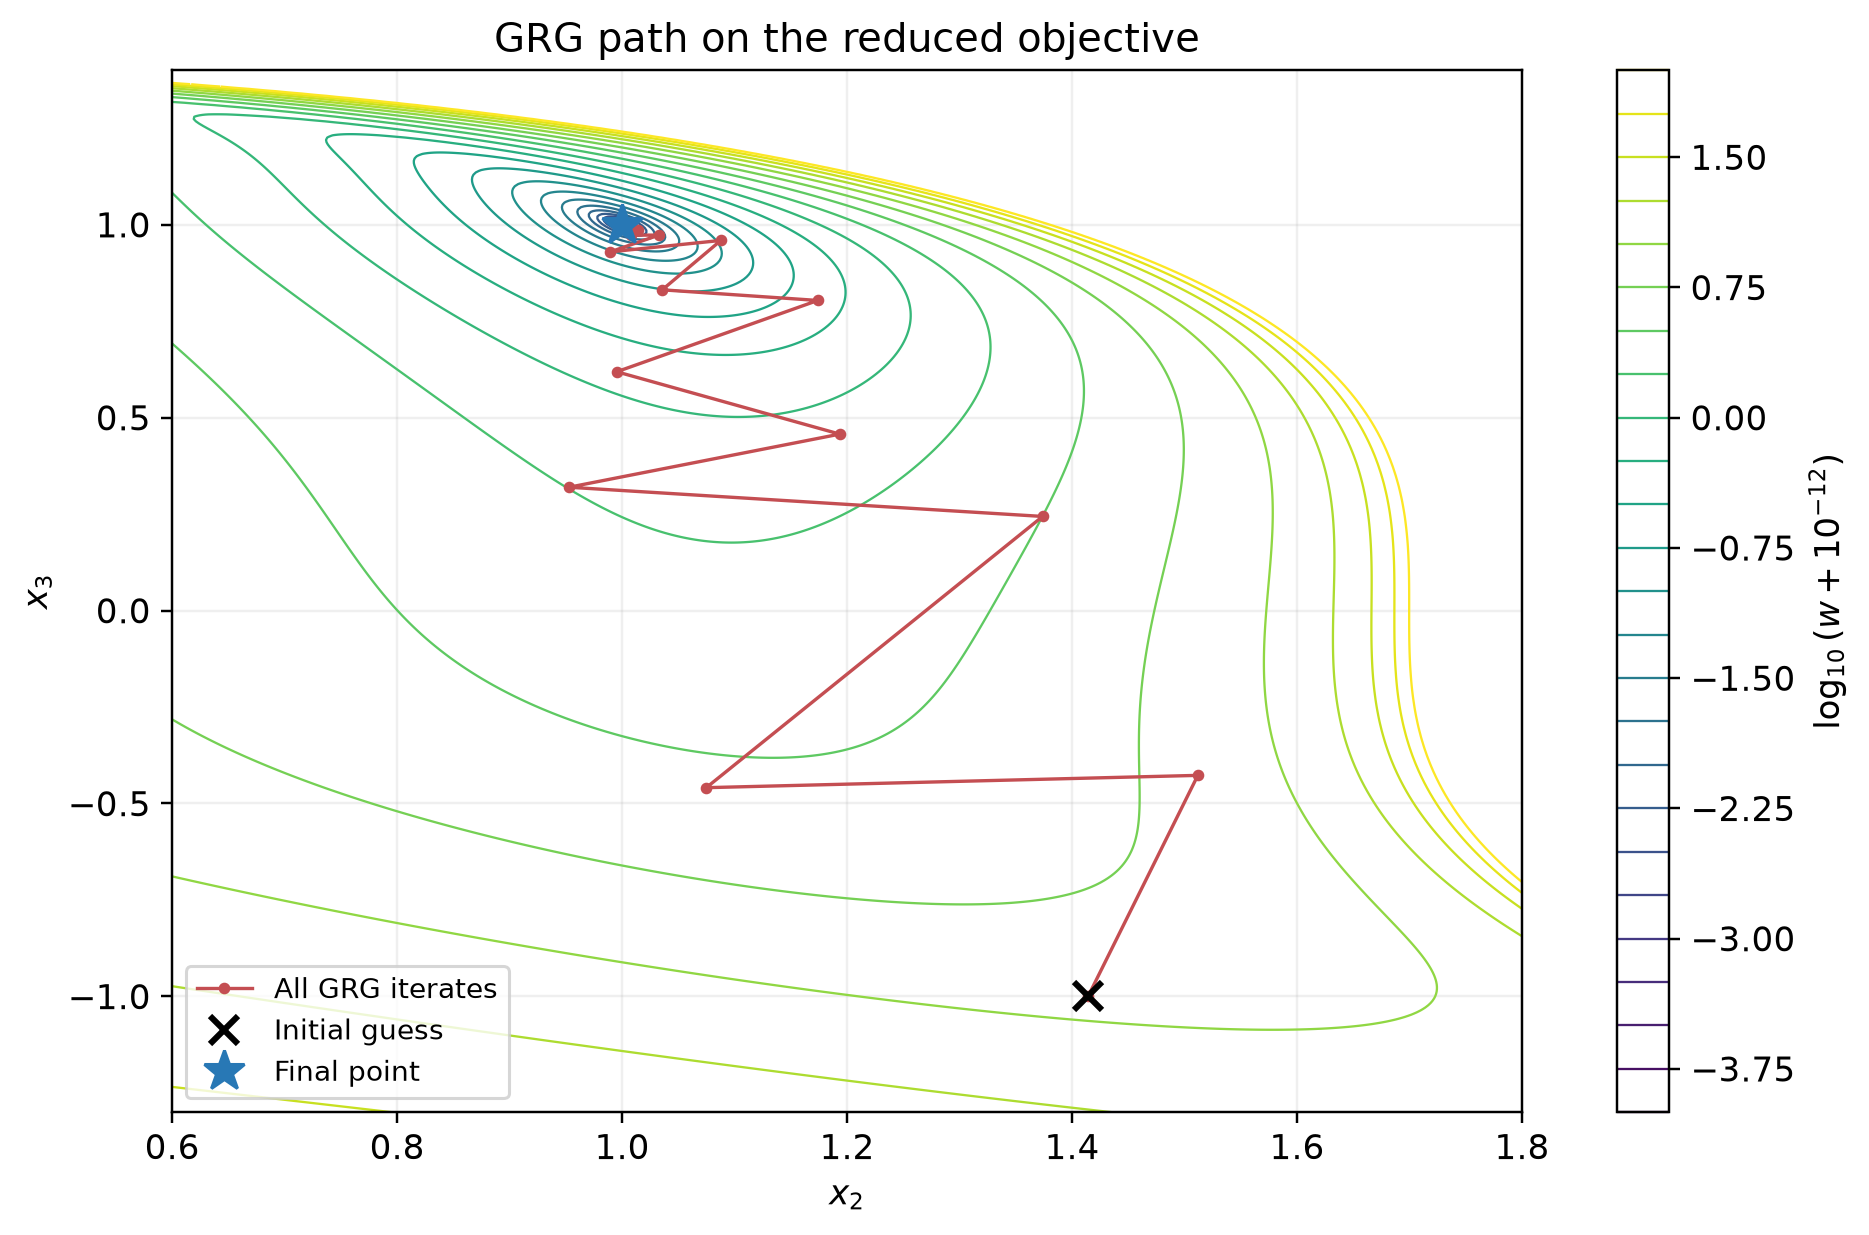

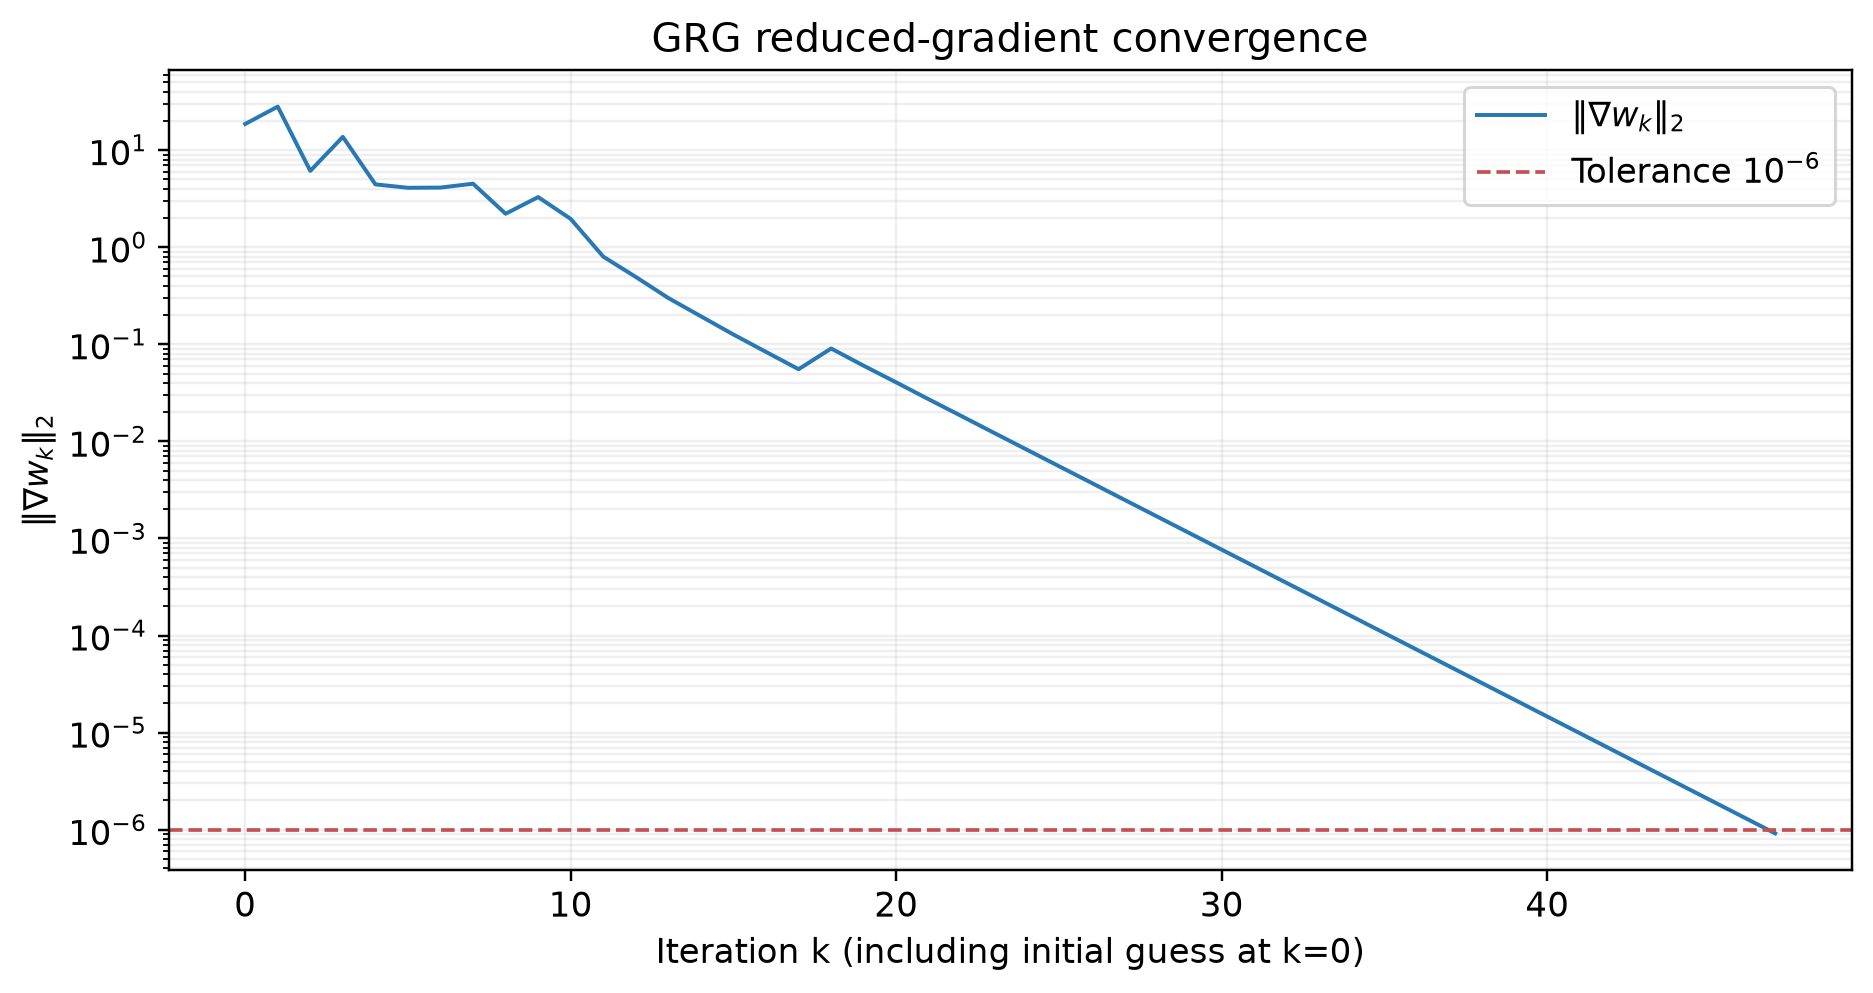

In [9]:
# Provided explicit elimination, used for plotting only, not for GRG restoration.
def w_of4(x2, x3):
    x1 = 3-x2**2-x3**3
    x4 = 1-x2+x3**2
    x5 = 1./x1
    return (x1-x2)**2+(x2-x3)**2+(x3-x4)**2+(x4-x5)**2

X2, X3 = np.meshgrid(np.linspace(.6, 1.8, 450), np.linspace(-1.3, 1.4, 450))
with np.errstate(divide='ignore', invalid='ignore'):
    W4 = np.where(3-X2**2-X3**3 > .05, w_of4(X2, X3), np.nan)

fig, ax = plt.subplots(figsize=(8.4, 5.5), layout='constrained')
contours = ax.contour(X2, X3, np.log10(W4+1e-12),
                      levels=np.linspace(-4, 2, 25), cmap='viridis', linewidths=.75)
fig.colorbar(contours, ax=ax, label=r'$\log_{10}(w+10^{-12})$')
ax.plot(q4_traj[:, 1], q4_traj[:, 2], '-o', color='#C44E52',
        lw=1.1, ms=2.8, label='All GRG iterates', zorder=4)
ax.plot(q4_start[1], q4_start[2], 'kx', ms=9, mew=2, label='Initial guess', zorder=6)
ax.plot(q4_xf[1], q4_xf[2], '*', color='#2878B5', ms=14, label='Final point', zorder=7)
ax.set(xlabel=r'$x_2$', ylabel=r'$x_3$', xlim=(.6, 1.8), ylim=(-1.3, 1.4),
       title='GRG path on the reduced objective')
ax.legend(loc='lower left', fontsize=9)
fig.savefig(FIGURES/'q4c_contours.png', dpi=220, bbox_inches='tight')
plt.close(fig)
display(Image(filename=str(FIGURES/'q4c_contours.png')))

fig, ax = plt.subplots(figsize=(8.4, 4.4), layout='constrained')
ax.semilogy(np.arange(len(q4_gnorm)), q4_gnorm, color='#2878B5', lw=1.3,
            label=r'$\|\nabla w_k\|_2$')
ax.axhline(1e-6, color='#C44E52', ls='--', lw=1.2, label=r'Tolerance $10^{-6}$')
ax.set(xlabel='Iteration k (including initial guess at k=0)',
       ylabel=r'$\|\nabla w_k\|_2$', title='GRG reduced-gradient convergence')
ax.grid(True, which='both', alpha=.2)
ax.legend()
fig.savefig(FIGURES/'q4c_convergence.png', dpi=220, bbox_inches='tight')
plt.close(fig)
display(Image(filename=str(FIGURES/'q4c_convergence.png')))

### 4(d)

In [10]:
# Solve the transposed system instead of explicitly inverting the state Jacobian.
q4_lambda = np.linalg.solve(jac_h4(q4_xf)[:, S4].T, -grad_f4(q4_xf)[S4])
q4_stationarity = grad_f4(q4_xf) + jac_h4(q4_xf).T @ q4_lambda
q4_slsqp = minimize(f4, q4_start, jac=grad_f4, method='SLSQP',
    constraints=[{'type': 'eq', 'fun': h4, 'jac': jac_h4}],
    options={'ftol': 1e-12, 'maxiter': 5000})
q4_comparison = pd.DataFrame([
    {'method': 'GRG', 'iterations': len(q4_traj)-1, 'f(x)': f4(q4_xf),
     '||h||': np.linalg.norm(h4(q4_xf)),
     '||grad w||': q4_gnorm[-1], '||x-1||': np.linalg.norm(q4_xf-np.ones(5)),
     **{f'x{j+1}': q4_xf[j] for j in range(5)}},
    {'method': 'SLSQP', 'iterations': q4_slsqp.nit, 'f(x)': q4_slsqp.fun,
     '||h||': np.linalg.norm(h4(q4_slsqp.x)),
     '||grad w||': np.linalg.norm(reduced_gradient4(q4_slsqp.x)),
     '||x-1||': np.linalg.norm(q4_slsqp.x-np.ones(5)),
     **{f'x{j+1}': q4_slsqp.x[j] for j in range(5)}}])
print('4(d) - GRG multipliers:', q4_lambda)
print('Full Lagrangian stationarity norm:', np.linalg.norm(q4_stationarity))
print_table('4(d) - GRG and SLSQP from the same initial guess', q4_comparison)
print('SLSQP success:', q4_slsqp.success, '|', q4_slsqp.message)
print('SLSQP settings: analytical derivatives, ftol=1e-12, maxiter=5000.')
print('Distance between the solutions:', np.linalg.norm(q4_xf-q4_slsqp.x))
print('Reference check at x=(1,1,1,1,1): f=', f4(np.ones(5)), ', h=', h4(np.ones(5)))
q4_comparison.to_csv(RESULTS/'q4d_comparison.csv', index=False)
latex_table('q4d_comparison.tex', ['Method', 'Iterations', '$f(x)$', r'$\|h\|_2$', r'$\|\nabla w\|_2$'],
    [[r['method'], str(int(r['iterations'])), sci(r['f(x)']), sci(r['||h||']),
      sci(r['||grad w||'])] for r in q4_comparison.to_dict('records')])
q4_summary = {'initial_reduced_gradient': reduced_gradient4(q4_start).tolist(),
    'grg': {'x': q4_xf.tolist(), 'f': float(f4(q4_xf)),
    'iterations': len(q4_traj)-1, 'reduced_gradient_norm': float(q4_gnorm[-1]),
    'constraint_norm': float(np.linalg.norm(h4(q4_xf))), 'converged': q4_converged,
    'multipliers': q4_lambda.tolist(), 'stationarity_norm': float(np.linalg.norm(q4_stationarity)),
    'max_constraint_norm': float(q4_history['||h||'].max()),
    'alpha_min': float(q4_steps['alpha'].min()), 'alpha_max': float(q4_steps['alpha'].max())},
    'slsqp': {'x': q4_slsqp.x.tolist(), 'f': float(q4_slsqp.fun),
    'iterations': int(q4_slsqp.nit), 'constraint_norm': float(np.linalg.norm(h4(q4_slsqp.x))),
    'reduced_gradient_norm': float(np.linalg.norm(reduced_gradient4(q4_slsqp.x))),
    'success': bool(q4_slsqp.success), 'message': str(q4_slsqp.message)}}
(RESULTS/'q4_summary.json').write_text(json.dumps(q4_summary, indent=2), encoding='utf-8')

4(d) - GRG multipliers: [ 0.0000002452  0.0000001736 -0.0000001264]
Full Lagrangian stationarity norm: 9.162429532971822e-07
4(d) - GRG and SLSQP from the same initial guess
method  iterations            f(x)           ||h||      ||grad w||         ||x-1||           x1          x2           x3           x4           x5
   GRG          47 8.635917294e-15 3.575421669e-13 9.162429533e-07 6.296601496e-08 0.9999999623 1.000000022 0.9999999981 0.9999999745  1.000000038
 SLSQP          14 2.222118817e-18 3.636721891e-15 6.866527005e-09 1.966866889e-09  1.000000001           1 0.9999999995 0.9999999986 0.9999999992

SLSQP success: True | Optimization terminated successfully
SLSQP settings: analytical derivatives, ftol=1e-12, maxiter=5000.
Distance between the solutions: 6.325970311627454e-08
Reference check at x=(1,1,1,1,1): f= 0.0 , h= [0. 0. 0.]
Out[10]: 1079
